In [1]:
!pip install torch torchvision

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.8.0+cpu
Torchvision: 0.23.0+cpu


MNIST Dataset Loaded Successfully!
Training samples: 60000
Testing samples: 10000


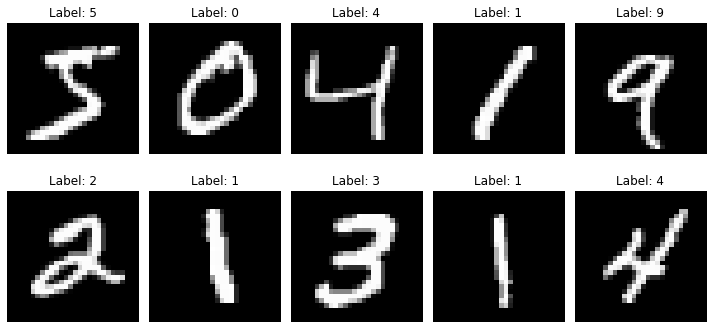

In [3]:
# Cell 2: Load and Visualize MNIST Dataset

import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Load training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load test dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("MNIST Dataset Loaded Successfully!")
print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Cell 3: Create DataLoaders

from torch.utils.data import DataLoader

# Batch size
batch_size = 64

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")
print("Batch size:", batch_size)

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

DataLoaders created successfully!
Batch size: 64
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


In [5]:
# Cell 4: Define MLP Model

import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )
    
    def forward(self, x):
        return self.network(x)


# Create model
mlp_model = MLP()

print(mlp_model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [6]:
# Cell 5: Loss Function and Optimizer

import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(mlp_model.parameters(), lr=0.001)

print("Loss function and optimizer created!")

Loss function and optimizer created!


In [7]:
# Cell 6: Train the MLP

import time

def train_model(model, train_loader, criterion, optimizer, epochs=5):
    
    model.train()
    
    loss_history = []
    accuracy_history = []
    
    start_time = time.time()
    
    for epoch in range(epochs):
        
        running_loss = 0.0
        correct = 0
        total = 0
        
        for images, labels in train_loader:
            
            # 1. Clear old gradients
            optimizer.zero_grad()
            
            # 2. Forward pass - make predictions
            outputs = model(images)
            
            # 3. Calculate loss
            loss = criterion(outputs, labels)
            
            # 4. Backpropagation
            loss.backward()
            
            # 5. Update weights
            optimizer.step()
            
            # Store loss
            running_loss += loss.item()
            
            # Calculate accuracy
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        
        loss_history.append(epoch_loss)
        accuracy_history.append(epoch_accuracy)
        
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )
    
    training_time = time.time() - start_time
    
    return loss_history, accuracy_history, training_time

In [8]:
# Train MLP

mlp_loss, mlp_accuracy, mlp_time = train_model(
    mlp_model,
    train_loader,
    criterion,
    optimizer,
    epochs=5
)

print(f"\nMLP Training Time: {mlp_time:.2f} seconds")

Epoch [1/5] Loss: 0.3406 Accuracy: 90.60%
Epoch [2/5] Loss: 0.1392 Accuracy: 95.91%
Epoch [3/5] Loss: 0.0957 Accuracy: 97.08%
Epoch [4/5] Loss: 0.0721 Accuracy: 97.74%
Epoch [5/5] Loss: 0.0567 Accuracy: 98.22%

MLP Training Time: 94.96 seconds


In [9]:
# Cell 7: Evaluate MLP on Test Dataset

def evaluate_model(model, test_loader):
    
    model.eval()
    
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            
            outputs = model(images)
            
            _, predicted = torch.max(outputs, 1)
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    accuracy = 100 * correct / total
    
    return accuracy


mlp_test_accuracy = evaluate_model(mlp_model, test_loader)

print(f"MLP Test Accuracy: {mlp_test_accuracy:.2f}%")

MLP Test Accuracy: 97.45%


In [10]:
import torch
import torch.nn as nn

class BasicCNN(nn.Module):
    def __init__(self):
        super(BasicCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = BasicCNN()
print(cnn_model)

BasicCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [11]:
import torch.optim as optim

In [12]:
import time
import torch

def train_model(model, train_loader, criterion, optimizer, epochs=5):
    loss_history = []
    accuracy_history = []
    start_time = time.time()

    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total

        loss_history.append(epoch_loss)
        accuracy_history.append(epoch_accuracy)

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Accuracy: {epoch_accuracy:.2f}%"
        )

    training_time = time.time() - start_time

    return loss_history, accuracy_history, training_time


In [13]:
cnn_criterion = nn.CrossEntropyLoss()
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

cnn_loss, cnn_accuracy, cnn_time = train_model(
    cnn_model,
    train_loader,
    cnn_criterion,
    cnn_optimizer,
    epochs=5
)

print(f"\nBasic CNN Training Time: {cnn_time:.2f} seconds")

cnn_test_accuracy = evaluate_model(cnn_model, test_loader)
print(f"Basic CNN Test Accuracy: {cnn_test_accuracy:.2f}%")

Epoch [1/5] Loss: 0.2229 Accuracy: 93.39%
Epoch [2/5] Loss: 0.0588 Accuracy: 98.19%
Epoch [3/5] Loss: 0.0400 Accuracy: 98.75%
Epoch [4/5] Loss: 0.0327 Accuracy: 98.95%
Epoch [5/5] Loss: 0.0236 Accuracy: 99.24%

Basic CNN Training Time: 230.40 seconds
Basic CNN Test Accuracy: 98.77%


In [15]:
import sklearn
print("scikit-learn version:", sklearn.__version__)

C:\ProgramData\Anaconda3\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


scikit-learn version: 1.0.2


In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

def detailed_evaluation(model, test_loader, model_name):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(
        all_labels, all_predictions, average="weighted", zero_division=0
    )
    recall = recall_score(
        all_labels, all_predictions, average="weighted", zero_division=0
    )
    f1 = f1_score(
        all_labels, all_predictions, average="weighted", zero_division=0
    )

    print(f"\n{model_name} — Test Metrics")
    print(f"Accuracy:  {accuracy * 100:.2f}%")
    print(f"Precision: {precision * 100:.2f}%")
    print(f"Recall:    {recall * 100:.2f}%")
    print(f"F1-score:  {f1 * 100:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        all_labels, all_predictions, digits=4, zero_division=0
    ))

    cm = confusion_matrix(all_labels, all_predictions)
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=range(10)
    )
    display.plot(cmap="Blues", values_format="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.show()

    return {
        "Model": model_name,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-score (%)": f1 * 100
    }


Basic CNN — Test Metrics
Accuracy:  98.77%
Precision: 98.78%
Recall:    98.77%
F1-score:  98.77%

Classification Report:
              precision    recall  f1-score   support

           0     0.9918    0.9929    0.9924       980
           1     0.9956    0.9947    0.9952      1135
           2     0.9884    0.9922    0.9903      1032
           3     0.9880    0.9792    0.9836      1010
           4     0.9790    0.9969    0.9879       982
           5     0.9714    0.9899    0.9806       892
           6     0.9927    0.9906    0.9916       958
           7     0.9950    0.9776    0.9863      1028
           8     0.9807    0.9897    0.9852       974
           9     0.9919    0.9732    0.9825      1009

    accuracy                         0.9877     10000
   macro avg     0.9875    0.9877    0.9875     10000
weighted avg     0.9878    0.9877    0.9877     10000



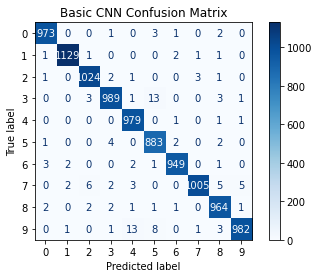

In [17]:
cnn_metrics = detailed_evaluation(
    cnn_model, test_loader, "Basic CNN"
)

In [18]:
basic_cnn_results = {
    "Model": "Basic CNN",
    "Training Accuracy (%)": 99.24,
    "Test Accuracy (%)": 98.77,
    "Precision (%)": 98.78,
    "Recall (%)": 98.77,
    "F1-score (%)": 98.77,
    "Training Loss": 0.0236,
    "Training Time (seconds)": 230.40
}

print(basic_cnn_results)

{'Model': 'Basic CNN', 'Training Accuracy (%)': 99.24, 'Test Accuracy (%)': 98.77, 'Precision (%)': 98.78, 'Recall (%)': 98.77, 'F1-score (%)': 98.77, 'Training Loss': 0.0236, 'Training Time (seconds)': 230.4}


In [19]:
import torch
import torch.nn as nn

class DeepCNN(nn.Module):
    def __init__(self):
        super(DeepCNN, self).__init__()

        self.features = nn.Sequential(
            # First convolution block
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution layer
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


deep_cnn_model = DeepCNN()
print(deep_cnn_model)

DeepCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [20]:
deep_cnn_criterion = nn.CrossEntropyLoss()

deep_cnn_optimizer = optim.Adam(
    deep_cnn_model.parameters(),
    lr=0.001
)

deep_cnn_loss, deep_cnn_accuracy, deep_cnn_time = train_model(
    deep_cnn_model,
    train_loader,
    deep_cnn_criterion,
    deep_cnn_optimizer,
    epochs=5
)

print(f"\nDeep CNN Training Time: {deep_cnn_time:.2f} seconds")

deep_cnn_test_accuracy = evaluate_model(
    deep_cnn_model,
    test_loader
)

print(f"Deep CNN Test Accuracy: {deep_cnn_test_accuracy:.2f}%")

Epoch [1/5] Loss: 0.1485 Accuracy: 95.27%
Epoch [2/5] Loss: 0.0436 Accuracy: 98.66%
Epoch [3/5] Loss: 0.0298 Accuracy: 99.07%
Epoch [4/5] Loss: 0.0228 Accuracy: 99.28%
Epoch [5/5] Loss: 0.0179 Accuracy: 99.41%

Deep CNN Training Time: 693.02 seconds
Deep CNN Test Accuracy: 99.12%


In [21]:
deep_cnn_test_accuracy = evaluate_model(
    deep_cnn_model,
    test_loader
)

print(f"Deep CNN Test Accuracy: {deep_cnn_test_accuracy:.2f}%")

Deep CNN Test Accuracy: 99.12%



Deep CNN — Test Metrics
Accuracy:  99.12%
Precision: 99.12%
Recall:    99.12%
F1-score:  99.12%

Classification Report:
              precision    recall  f1-score   support

           0     0.9849    0.9990    0.9919       980
           1     0.9974    0.9956    0.9965      1135
           2     0.9846    0.9932    0.9889      1032
           3     0.9940    0.9881    0.9911      1010
           4     0.9889    0.9949    0.9919       982
           5     0.9866    0.9910    0.9888       892
           6     0.9937    0.9916    0.9927       958
           7     0.9932    0.9883    0.9907      1028
           8     0.9908    0.9908    0.9908       974
           9     0.9970    0.9792    0.9880      1009

    accuracy                         0.9912     10000
   macro avg     0.9911    0.9912    0.9911     10000
weighted avg     0.9912    0.9912    0.9912     10000



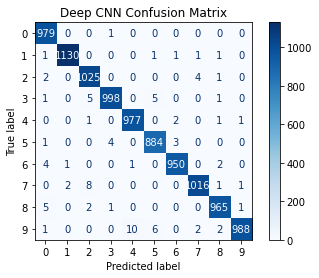

In [22]:
deep_cnn_metrics = detailed_evaluation(
    deep_cnn_model,
    test_loader,
    "Deep CNN"
)

In [23]:
deep_cnn_results = {
    "Model": "Deep CNN",
    "Training Accuracy (%)": 99.41,
    "Test Accuracy (%)": 99.12,
    "Precision (%)": 99.12,
    "Recall (%)": 99.12,
    "F1-score (%)": 99.12,
    "Training Loss": 0.0179,
    "Training Time (seconds)": 693.02
}

print(deep_cnn_results)

{'Model': 'Deep CNN', 'Training Accuracy (%)': 99.41, 'Test Accuracy (%)': 99.12, 'Precision (%)': 99.12, 'Recall (%)': 99.12, 'F1-score (%)': 99.12, 'Training Loss': 0.0179, 'Training Time (seconds)': 693.02}
